In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv(r"D:\DATA ANALYSIS\E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis\Data\02_cleaned\customer_cleaned_data.csv")

In [ ]:
df.head(10)

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle aged,365
5,6,46,Male,Sneakers,Footwear,20,Wyoming,M,White,Summer,2.9,Yes,Standard,Yes,14,Venmo,Weekly,Middle aged,7
6,7,63,Male,Shirt,Clothing,85,Montana,M,Gray,Fall,3.2,Yes,Free Shipping,Yes,49,Cash,Quarterly,senior,90
7,8,27,Male,Shorts,Clothing,34,Louisiana,L,Charcoal,Winter,3.2,Yes,Free Shipping,Yes,19,Credit Card,Weekly,Young Adult,7
8,9,26,Male,Coat,Outerwear,97,West Virginia,L,Silver,Summer,2.6,Yes,Express,Yes,8,Venmo,Annually,Young Adult,365
9,10,57,Male,Handbag,Accessories,31,Missouri,M,Pink,Spring,4.8,Yes,2-Day Shipping,Yes,4,Cash,Quarterly,Middle aged,90


In [97]:
df.describe()

,customer_id,age,purchase_amount,review_rating,previous_purchases,purchase_frequency_days
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750051,25.351538,89.133077
std,1125.977353,15.207589,23.685392,0.713590,14.447125,119.037566
min,1.000000,18.000000,20.000000,2.500000,1.000000,7.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000,14.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000,30.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000,90.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000,365.000000


In [98]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              3900 non-null   int64  
 1   age                      3900 non-null   int64  
 2   gender                   3900 non-null   str    
 3   item_purchased           3900 non-null   str    
 4   category                 3900 non-null   str    
 5   purchase_amount          3900 non-null   int64  
 6   location                 3900 non-null   str    
 7   size                     3900 non-null   str    
 8   color                    3900 non-null   str    
 9   season                   3900 non-null   str    
 10  review_rating            3900 non-null   float64
 11  subscription_status      3900 non-null   str    
 12  shipping_type            3900 non-null   str    
 13  discount_applied         3900 non-null   str    
 14  previous_purchases       3900 non-n

In [99]:
df.isnull().sum()

customer_id                0
age                        0
gender                     0
item_purchased             0
category                   0
purchase_amount            0
location                   0
size                       0
color                      0
season                     0
review_rating              0
subscription_status        0
shipping_type              0
discount_applied           0
previous_purchases         0
payment_method             0
frequency_of_purchases     0
age_group                  0
purchase_frequency_days    0
dtype: int64

In [ ]:
#RECENCY
df['r']=pd.qcut(df['purchase_frequency_days'].rank(method='first'),q=5,labels=[5,4,3,2,1]).astype(int)

In [101]:
#FREQUENCY
df['f']=pd.qcut(df['previous_purchases'].rank(method='first'),q=5,labels=[1,2,3,4,5]).astype(int)

In [102]:
#MONETARY
df['m']=pd.qcut(df['purchase_amount'].rank(method='first'),q=5,labels=[1,2,3,4,5]).astype(int)

In [103]:
df['RFM_score']=df['r'].astype(str)+df['f'].astype(str)+df['m'].astype(str)


df['RFM_Sum']   = df[['r','f','m']].sum(axis=1)

In [104]:
df.head()

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,...,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days,r,f,m,RFM_score,RFM_Sum
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,14,Venmo,Fortnightly,Middle aged,14,1,2,3,123,6
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,2,Cash,Fortnightly,Young Adult,14,1,1,3,113,5
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,23,Credit Card,Weekly,Middle aged,7,1,3,4,134,8
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,49,PayPal,Weekly,Young Adult,7,1,5,5,155,11
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,31,PayPal,Annually,Middle aged,365,5,4,2,542,11


In [105]:
#RFM Analysis

In [106]:
def segment(row):
    r, f, m = row['r'], row['f'], row['m']
    if r>=4 and f>=4 and m>4: return 'Champions'
    elif r >= 3 and f >= 3: return 'Loyal Customers'
    elif r >= 4 and f <= 2: return 'New / Promising'
    elif r <= 2 and f >= 4: return 'At Risk'
    elif r <= 2 and f <= 2 and m >= 3: return 'Cannot Lose Them'
    elif r <= 2 and f <= 2: return 'Lost'
    else: return 'Need Attention'

df['Segment'] = df.apply(segment, axis=1)

In [107]:
import numpy as np
import matplotlib.pyplot as plt

In [108]:
import seaborn as sns

In [109]:
print("Segment counts:")
segment_counts=df['Segment'].value_counts().sort_values(ascending=False)
print(segment_counts)

Segment counts:
Segment
Loyal Customers     1269
New / Promising      626
Need Attention       622
At Risk              622
Cannot Lose Them     371
Lost                 254
Champions            136
Name: count, dtype: int64


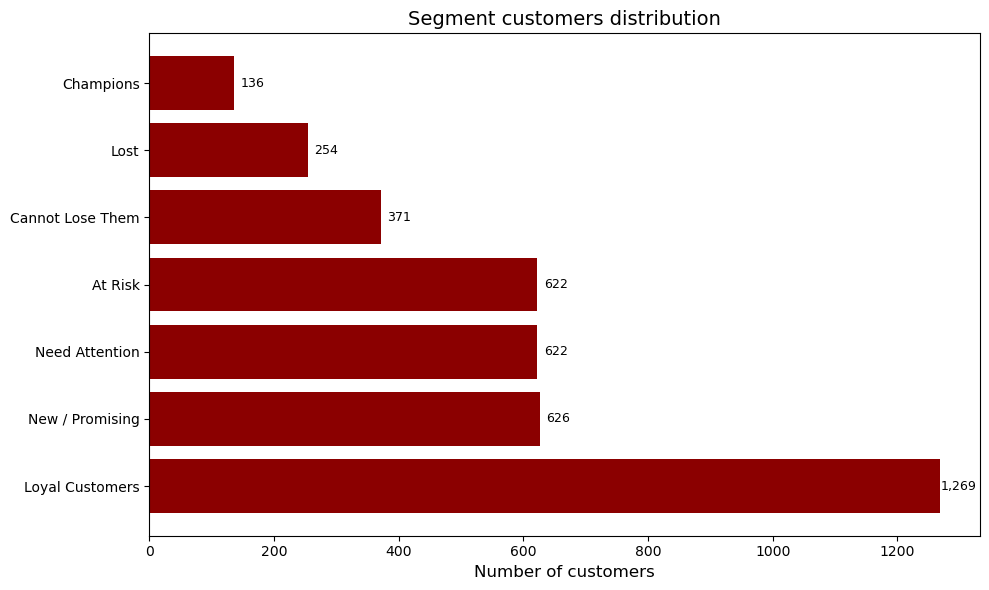

In [110]:
plt.figure(figsize=(10, 6))
plt.barh(segment_counts.index,segment_counts.values,color='#8B0000')

plt.title("Segment customers distribution",size= 14)
plt.xlabel("Number of customers",size=12)

for i,v in enumerate(segment_counts.values):
    plt.text(v+30, i, f"{v:,}", va='center', ha='center', fontsize=9)
plt.tight_layout()

plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Segment customers distribution.png", dpi=300, bbox_inches='tight')
plt.show()

In [111]:
# Percentages
print("\nCustomer % by segment:")
customer_pct=(segment_counts / segment_counts.sum() * 100).round(2)
print(customer_pct)


Customer % by segment:
Segment
Loyal Customers     32.54
New / Promising     16.05
Need Attention      15.95
At Risk             15.95
Cannot Lose Them     9.51
Lost                 6.51
Champions            3.49
Name: count, dtype: float64


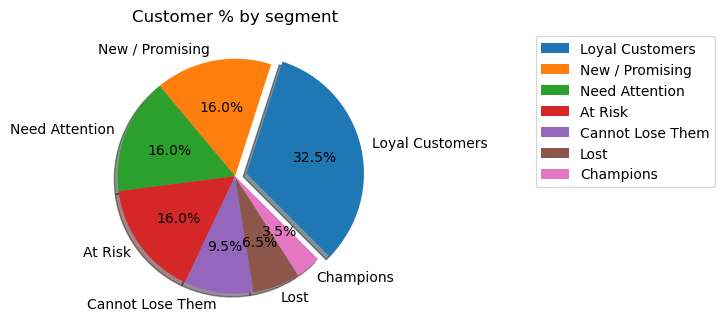

In [112]:
plt.pie(x=customer_pct.values,labels=customer_pct.index,autopct="%1.1f%%",explode=[0.1,0,0,0,0,0,0],shadow=True,startangle=-45)
plt.title("Customer % by segment")
plt.legend(bbox_to_anchor=(1.5,1),loc="upper left")
plt.tight_layout()
plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Customer % by segment.png", dpi=300, bbox_inches='tight')
plt.show()

In [113]:
#Revenue by Segment
segment_revenue = df.groupby('Segment')['purchase_amount'].sum().sort_values(ascending=True)

print(segment_revenue)

Segment
Lost                 8894
Champions           12632
Cannot Lose Them    28133
At Risk             37049
New / Promising     37447
Need Attention      37733
Loyal Customers     71193
Name: purchase_amount, dtype: int64


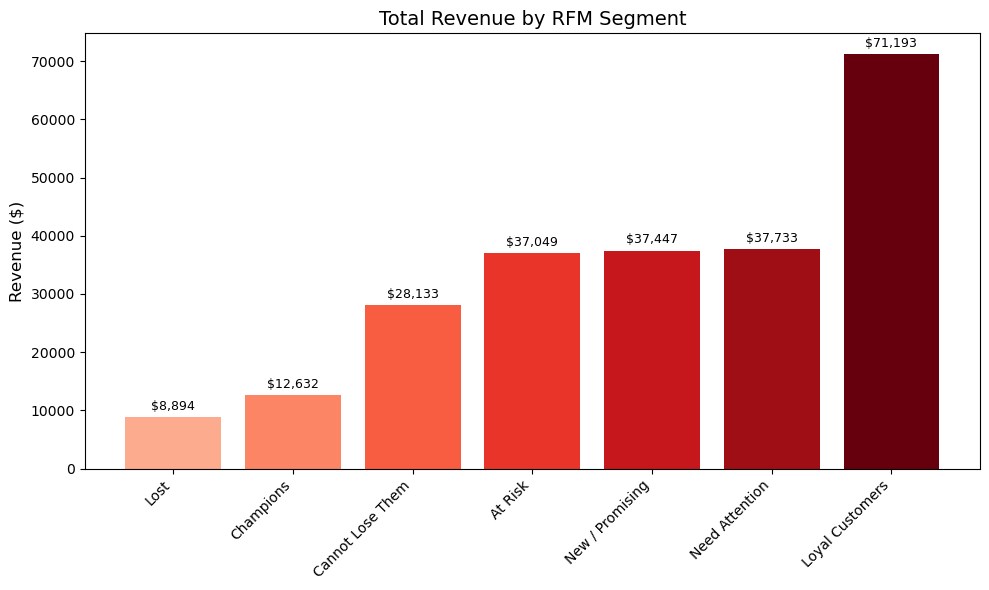

In [114]:
plt.figure(figsize=(10, 6))
cmap=plt.get_cmap('Reds')
colors=cmap(np.linspace(0.3,1.0,len(segment_revenue.values)))

plt.bar(segment_revenue.index,segment_revenue.values,color=colors)

plt.title('Total Revenue by RFM Segment',size= 14)
plt.ylabel('Revenue ($)',size=12)

for i,v in enumerate(segment_revenue.values):
    plt.text(i, v + (max(segment_revenue.values) * 0.01), f"${v:,}",va='bottom', ha='center', fontsize=9)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Total Revenue by RFM Segment.png", dpi=300, bbox_inches='tight')

plt.show()

In [115]:
# Percentages
print("\nRevenue % by segment:")
revenu_pct=(segment_revenue / segment_revenue.sum() * 100).round(2).sort_values(ascending=False)
print(revenu_pct)


Revenue % by segment:
Segment
Loyal Customers     30.54
Need Attention      16.19
New / Promising     16.07
At Risk             15.90
Cannot Lose Them    12.07
Champions            5.42
Lost                 3.82
Name: purchase_amount, dtype: float64


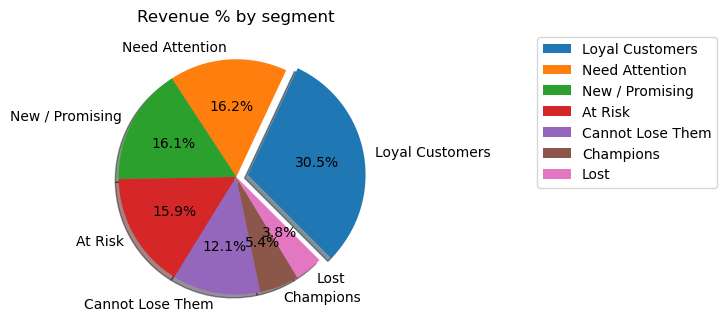

In [116]:
plt.pie(x=revenu_pct.values,labels=revenu_pct.index,autopct="%1.1f%%",explode=[0.1,0,0,0,0,0,0],shadow=True,startangle=-45)
plt.title("Revenue % by segment")
plt.legend(bbox_to_anchor=(1.5,1),loc="upper left")
plt.tight_layout()

plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Revenue % by segment.png", dpi=300, bbox_inches='tight')

plt.show()

In [117]:
#Compare Customer % vs Revenue %

In [118]:
comparison = pd.DataFrame({
    'Customer_Pct': segment_counts / segment_counts.sum() * 100,
    'Revenue_Pct': segment_revenue / segment_revenue.sum() * 100
}).round(2)

print("\nCustomer % vs Revenue % by Segment:")
print(comparison)


Customer % vs Revenue % by Segment:
                  Customer_Pct  Revenue_Pct
Segment                                    
At Risk                  15.95        15.90
Cannot Lose Them          9.51        12.07
Champions                 3.49         5.42
Lost                      6.51         3.82
Loyal Customers          32.54        30.54
Need Attention           15.95        16.19
New / Promising          16.05        16.07


In [119]:
##save file
#RFM Analysis
df.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/02_cleaned/rfm_segmentation.csv", index=False)
df.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/03_RFM_&_Dropoff/01_rfm_segmentation.csv", index=False)

#Customer % vs Revenue % by Segment
comparison.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/03_RFM_&_Dropoff/Customer pct vs Revenue pct by Segment.csv", index=True)

In [120]:
##Funnel Drop-off Analysis

In [121]:
#FREQUENCY Drop-off Analysis by customer

In [122]:
stages=[
    ("1+ purchase",   df['previous_purchases'] >= 1),
    ("5+ purchases",  df['previous_purchases'] >= 5),
    ("10+ purchases", df['previous_purchases'] >= 10),
    ("20+ purchases", df['previous_purchases'] >= 20),
    ("30+ purchases", df['previous_purchases'] >= 30),
    ("40+ purchases", df['previous_purchases'] >= 40),
]

funnel=pd.DataFrame({
    'Stage':[s[0] for s in stages],
    'Customers':[s[1].sum() for s in stages]
})
funnel['Pct_of_total']=(funnel['Customers']/len(df)*100).round(2)
funnel['Dropoff_From_Prev']=(funnel['Customers'].shift(1) - funnel['Customers']).fillna(0)
funnel['Dropoff_pct']=(funnel['Dropoff_From_Prev']/funnel['Customers'].shift(1)*100).round(2).fillna(0)
print(funnel)
funnel.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/03_RFM_&_Dropoff/FREQUENCY Drop-off Analysis by customer.csv", index=False)

           Stage  Customers  Pct_of_total  Dropoff_From_Prev  Dropoff_pct
0    1+ purchase       3900        100.00                0.0         0.00
1   5+ purchases       3563         91.36              337.0         8.64
2  10+ purchases       3192         81.85              371.0        10.41
3  20+ purchases       2422         62.10              770.0        24.12
4  30+ purchases       1631         41.82              791.0        32.66
5  40+ purchases        847         21.72              784.0        48.07


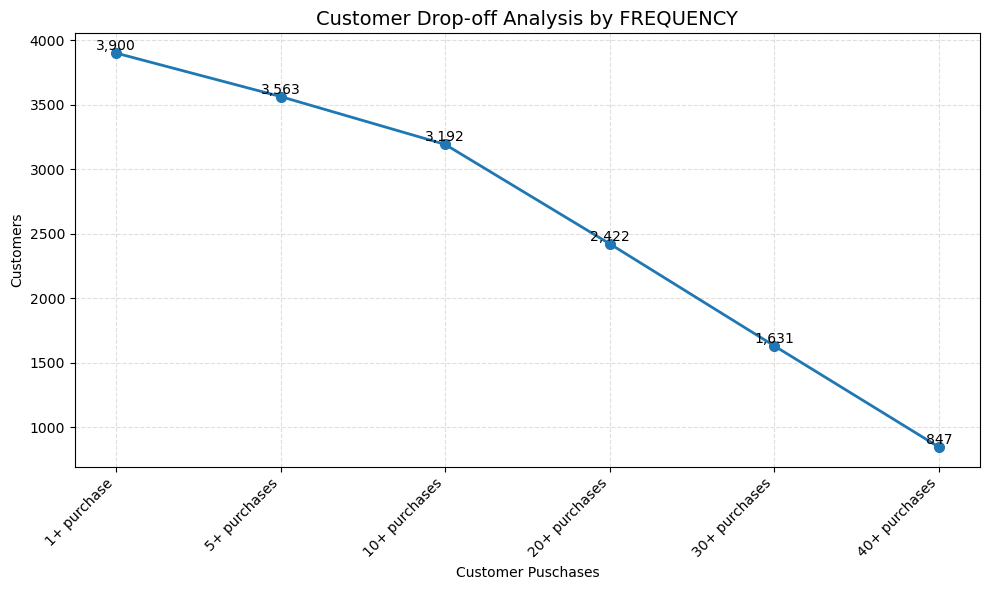

In [123]:
plt.figure(figsize=(10, 6))

plt.plot(funnel['Stage'],funnel['Customers'],marker='o',linewidth=2,markersize=7)

plt.title('Customer Drop-off Analysis by FREQUENCY', fontsize=14)
plt.xlabel('Customer Puschases')
plt.ylabel('Customers')

plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.4)

for i, value in enumerate(funnel['Customers']):
    plt.text(i, value, f'{value:,.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Customer Drop-off Analysis by FREQUENCY.png", dpi=300, bbox_inches='tight')
plt.show()

In [124]:
#FREQUENCY Drop-off Analysis by revenue

In [125]:
stages=[
    ("1+ purchase",   df['previous_purchases'] >= 1),
    ("5+ purchases",  df['previous_purchases'] >= 5),
    ("10+ purchases", df['previous_purchases'] >= 10),
    ("20+ purchases", df['previous_purchases'] >= 20),
    ("30+ purchases", df['previous_purchases'] >= 30),
    ("40+ purchases", df['previous_purchases'] >= 40),
]

funnel=pd.DataFrame({
    'Stage':[s[0] for s in stages],
    'Customers':[s[1].sum() for s in stages]
})

funnel['Revenue'] = [df.loc[condition, 'purchase_amount'].sum()
    for stage, condition in stages]

funnel['Revenue_Pct_of_Total']=(funnel['Revenue']/funnel['Revenue'].iloc[0]*100).round(2)
funnel['Revenue_Dropoff']=(funnel['Revenue'].shift(1) - funnel['Revenue']).fillna(0)
funnel['Dropoff_Pct'] = (funnel['Revenue_Dropoff'] / funnel['Revenue'].shift(1) * 100).round(2).fillna(0)

print(funnel)

funnel.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/03_RFM_&_Dropoff/FREQUENCY Drop-off Analysis by revenue.csv", index=False)

           Stage  Customers  Revenue  Revenue_Pct_of_Total  Revenue_Dropoff  \
0    1+ purchase       3900   233081                100.00              0.0   
1   5+ purchases       3563   212979                 91.38          20102.0   
2  10+ purchases       3192   189939                 81.49          23040.0   
3  20+ purchases       2422   144770                 62.11          45169.0   
4  30+ purchases       1631    97851                 41.98          46919.0   
5  40+ purchases        847    51035                 21.90          46816.0   

   Dropoff_Pct  
0         0.00  
1         8.62  
2        10.82  
3        23.78  
4        32.41  
5        47.84  


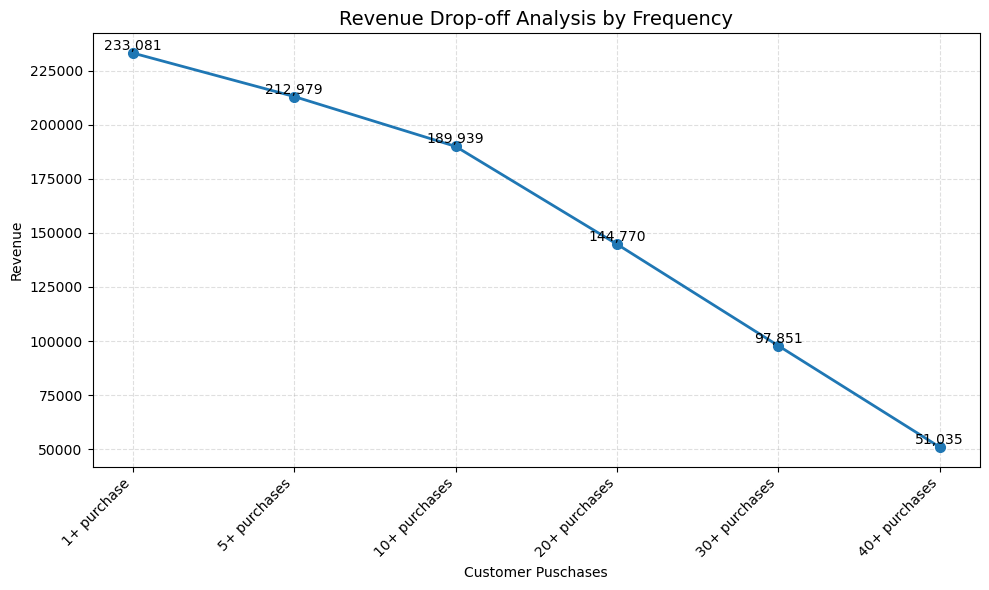

In [126]:
plt.figure(figsize=(10, 6))

plt.plot(funnel['Stage'],funnel['Revenue'],marker='o',linewidth=2,markersize=7)

plt.title('Revenue Drop-off Analysis by Frequency', fontsize=14)
plt.xlabel('Customer Puschases')
plt.ylabel('Revenue')

plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.4)

for i, value in enumerate(funnel['Revenue']):
    plt.text(i, value, f'{value:,.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Revenue Drop-off Analysis by Frequency.png", dpi=300, bbox_inches='tight')
plt.show()

In [127]:
#RECENCY Drop-off Analysis by customer

In [128]:
stages = [
    ("Active in last 365 days", df['purchase_frequency_days'] <= 365),
    ("Active in last 90 days",  df['purchase_frequency_days'] <= 90),
    ("Active in last 30 days",  df['purchase_frequency_days'] <= 30),
    ("Active in last 14 days",  df['purchase_frequency_days'] <= 14),
    ("Active in last 7 days",   df['purchase_frequency_days'] <= 7),  
]
funnel=pd.DataFrame({
    'Stage':[s[0] for s in stages],
    'Customers':[s[1].sum() for s in stages]
})
funnel['Pct_of_total']=(funnel['Customers']/len(df)*100).round(2)
funnel['Dropoff_From_Prev']=(funnel['Customers'].shift(1) - funnel['Customers']).fillna(0)
funnel['Dropoff_pct']=(funnel['Dropoff_From_Prev']/funnel['Customers'].shift(1)*100).round(2).fillna(0)
print(funnel)

funnel.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/03_RFM_&_Dropoff/RECENCY Drop-off Analysis by customer.csv", index=False)

                     Stage  Customers  Pct_of_total  Dropoff_From_Prev  \
0  Active in last 365 days       3900        100.00                0.0   
1   Active in last 90 days       3328         85.33              572.0   
2   Active in last 30 days       2181         55.92             1147.0   
3   Active in last 14 days       1628         41.74              553.0   
4    Active in last 7 days        539         13.82             1089.0   

   Dropoff_pct  
0         0.00  
1        14.67  
2        34.47  
3        25.36  
4        66.89  


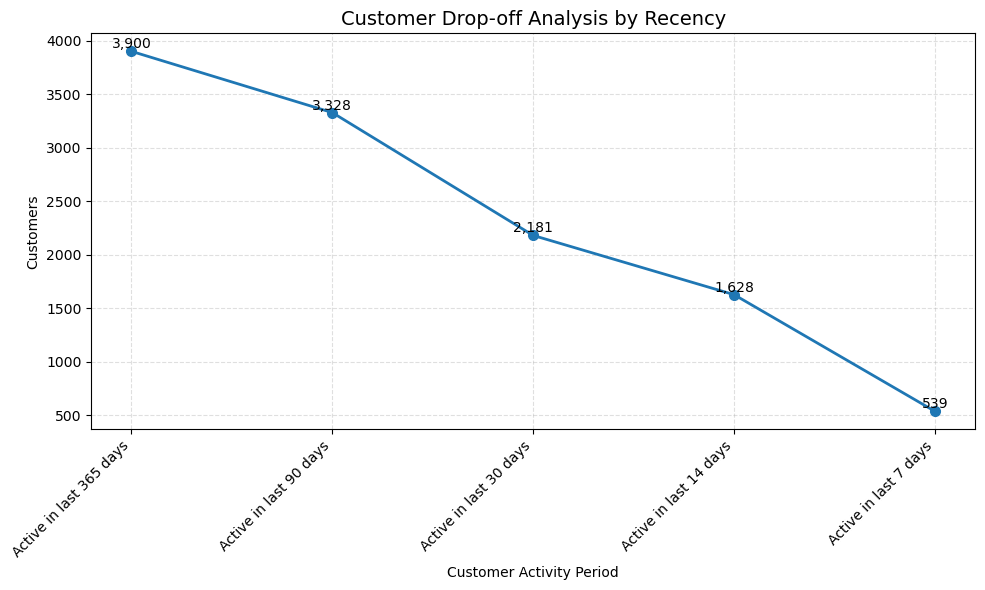

In [129]:
plt.figure(figsize=(10, 6))

plt.plot(funnel['Stage'],funnel['Customers'],marker='o',linewidth=2,markersize=7)

plt.title('Customer Drop-off Analysis by Recency', fontsize=14)
plt.xlabel('Customer Activity Period')
plt.ylabel('Customers')

plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.4)

for i, value in enumerate(funnel['Customers']):
    plt.text(i, value, f'{value:,.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Customer Drop-off Analysis by Recency.png", dpi=300, bbox_inches='tight')
plt.show()

In [130]:
#RECENCY Drop-off Analysis by Revenue

In [131]:
stages = [
    ("Active in last 365 days", df['purchase_frequency_days'] <= 365),
    ("Active in last 90 days",  df['purchase_frequency_days'] <= 90),
    ("Active in last 30 days",  df['purchase_frequency_days'] <= 30),
    ("Active in last 14 days",  df['purchase_frequency_days'] <= 14),
    ("Active in last 7 days",   df['purchase_frequency_days'] <= 7),  
]

funnel=pd.DataFrame({
    'Stage':[s[0] for s in stages],
    'Customers':[s[1].sum() for s in stages]
})

funnel['Revenue'] = [df.loc[condition, 'purchase_amount'].sum()
    for stage, condition in stages]

funnel['Revenue_Pct_of_Total']=(funnel['Revenue']/funnel['Revenue'].iloc[0]*100).round(2)
funnel['Revenue_Dropoff']=(funnel['Revenue'].shift(1) - funnel['Revenue']).fillna(0)
funnel['Dropoff_Pct'] = (funnel['Revenue_Dropoff'] / funnel['Revenue'].shift(1) * 100).round(2).fillna(0)

print(funnel)

funnel.to_csv("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/Data/03_RFM_&_Dropoff/RECENCY Drop-off Analysis by Revenue.csv", index=False)

                     Stage  Customers  Revenue  Revenue_Pct_of_Total  \
0  Active in last 365 days       3900   233081                100.00   
1   Active in last 90 days       3328   198662                 85.23   
2   Active in last 30 days       2181   129803                 55.69   
3   Active in last 14 days       1628    96993                 41.61   
4    Active in last 7 days        539    31786                 13.64   

   Revenue_Dropoff  Dropoff_Pct  
0              0.0         0.00  
1          34419.0        14.77  
2          68859.0        34.66  
3          32810.0        25.28  
4          65207.0        67.23  


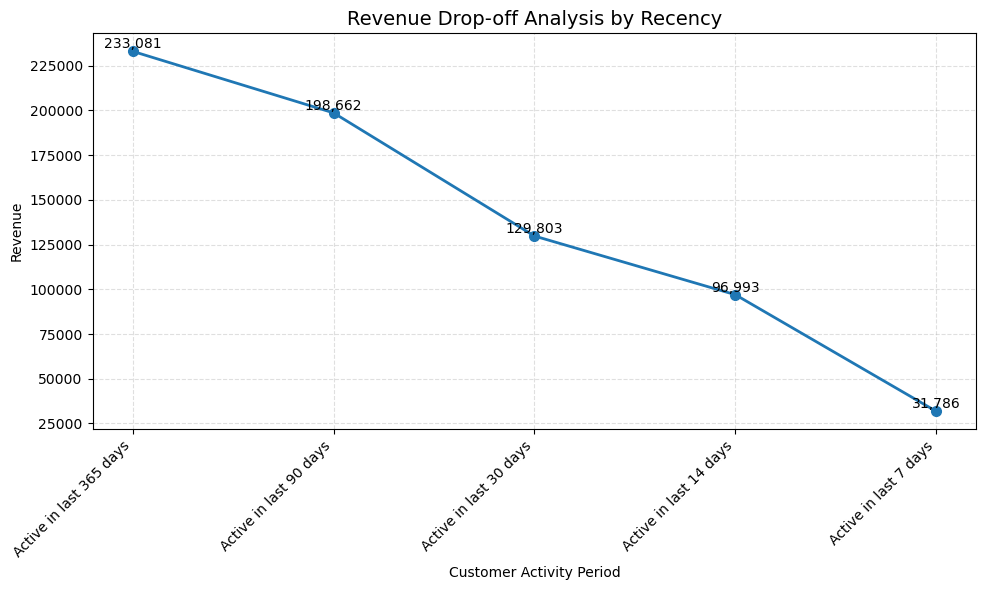

In [132]:
plt.figure(figsize=(10, 6))

plt.plot(funnel['Stage'],funnel['Revenue'],marker='o',linewidth=2,markersize=7)

plt.title('Revenue Drop-off Analysis by Recency', fontsize=14)
plt.xlabel('Customer Activity Period')
plt.ylabel('Revenue')

plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.4)

for i, value in enumerate(funnel['Revenue']):
    plt.text(i, value, f'{value:,.0f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig("D:/DATA ANALYSIS/E-commerce Funnel Drop-off & RFM Customer Segmentation Analysis/visuals/Revenue Drop-off Analysis by Recency.png", dpi=300, bbox_inches='tight')
plt.show()